In [25]:
import pandas as pd

df = pd.read_csv("penguins_size.csv")

df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
print("Number of penguins:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nPenguins per species:")
print(df["species"].value_counts())

Number of penguins: 344
Number of columns: 7

Penguins per species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


# Predicting Penguin Species

## Problem Statement

This project uses the Palmer Penguins dataset downloaded from Kaggle. It contains 344 penguins and 7 columns: species, island, bill length, bill depth, flipper length, body mass, and sex.

The goal is to predict a penguin’s species using its physical measurements. This is a classification problem with three possible outcomes: Adelie, Gentoo, and Chinstrap.

### Target Variable

The target variable is `species`:
- Adelie: 152 penguins
- Gentoo: 124 penguins
- Chinstrap: 68 penguins

The classes are unequal in size, with Chinstrap being the smallest group. We will evaluate performance for each species as well as overall accuracy.

In [5]:
print("Missing values in each column:")
print(df.isna().sum())

Missing values in each column:
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64


print(df["sex"].value_counts(dropna=False))

## Basic Data Cleaning

### Inconsistent Categorical Values

The sex column contains one invalid entry recorded as `.`. This is replaced with a missing value so it can be handled consistently with the other missing entries.

In [6]:
df["sex"] = df["sex"].replace(".", float("nan"))

print(df["sex"].value_counts(dropna=False))

sex
MALE      168
FEMALE    165
NaN        11
Name: count, dtype: int64


### Missing Values

Rows containing missing values are removed to keep the analysis simple and avoid estimating unknown measurements or sex. The number of removed rows is reported below.

In [7]:
rows_before = len(df)

df = df.dropna().copy()

print("Rows removed:", rows_before - len(df))
print("Penguins remaining:", len(df))
print("Missing values remaining:", df.isna().sum().sum())

Rows removed: 11
Penguins remaining: 333
Missing values remaining: 0


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Duplicate Check

No exact duplicate rows were found. After handling missing values, 333 penguins remain.

In [9]:
for column in ["species", "island"]:
    print(f"{column}: {sorted(df[column].unique())}")

species: ['Adelie', 'Chinstrap', 'Gentoo']
island: ['Biscoe', 'Dream', 'Torgersen']


### Categorical Label Check

The species and island columns contain consistent category labels. No corrections are needed.

In [10]:
%pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


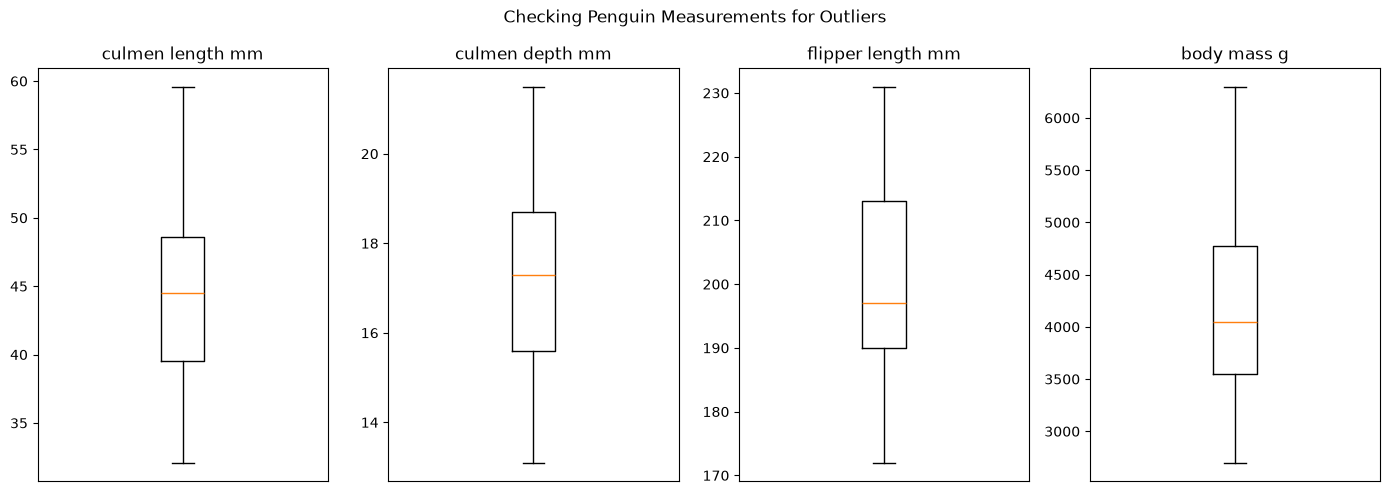

In [11]:
import matplotlib.pyplot as plt

measurements = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

fig, axes = plt.subplots(1, 4, figsize=(14, 5))

for ax, column in zip(axes, measurements):
    ax.boxplot(df[column])
    ax.set_title(column.replace("_", " "))
    ax.set_xticks([])

fig.suptitle("Checking Penguin Measurements for Outliers")
plt.tight_layout()
plt.show()

### Outlier Check

Boxplots were used to examine bill length, bill depth, flipper length, and body mass. No values fell beyond the whiskers under the standard 1.5 × interquartile range rule. Therefore, no rows were removed as outliers.

In [12]:
display(
    df.groupby("species")[measurements].mean().round(2)
)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.82,18.35,190.10,3706.16
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.57,15.00,217.24,5092.44


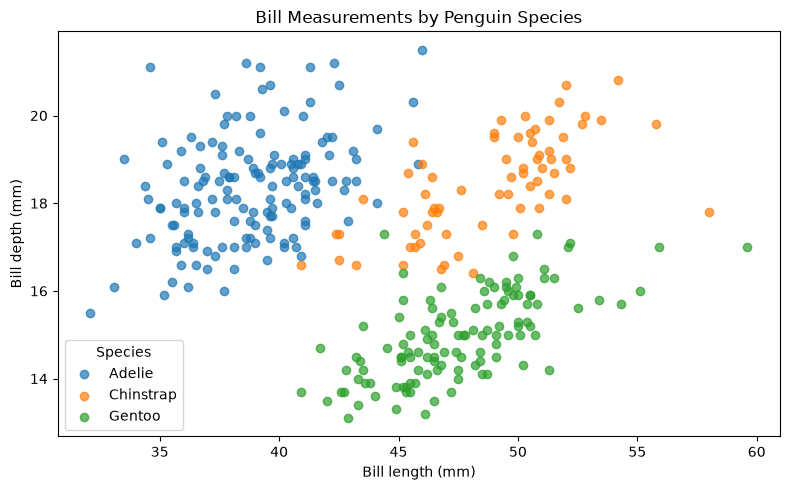

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

for species, group in df.groupby("species"):
    ax.scatter(
        group["culmen_length_mm"],
        group["culmen_depth_mm"],
        label=species,
        alpha=0.7
    )

ax.set_xlabel("Bill length (mm)")
ax.set_ylabel("Bill depth (mm)")
ax.set_title("Bill Measurements by Penguin Species")
ax.legend(title="Species")
plt.tight_layout()
plt.show()

## Feature Engineering

### Graphical Analysis

The scatterplot suggests that bill length and depth are useful predictors of species. Adelie generally have shorter bills, while Gentoo generally have shallower bills. Chinstrap tend to have longer, deeper bills. Some overlap remains, so these measurements do not perfectly separate every penguin.

In [14]:
%pip install scikit-learn scipy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
from sklearn.model_selection import train_test_split

X = df[measurements].copy()
y = df["species"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training penguins:", len(X_train))
print("Testing penguins:", len(X_test))
print("\nTraining species counts:")
print(y_train.value_counts())

Training penguins: 266
Testing penguins: 67

Training species counts:
species
Adelie       117
Gentoo        95
Chinstrap     54
Name: count, dtype: int64


In [16]:
from sklearn.feature_selection import f_classif

f_scores, p_values = f_classif(X_train, y_train)

anova_results = pd.DataFrame({
    "feature": X_train.columns,
    "F_score": f_scores,
    "p_value": p_values
}).sort_values("F_score", ascending=False)

display(anova_results)

,feature,F_score,p_value
2,flipper_length_mm,457.315717,2.434704e-86
0,culmen_length_mm,324.753828,8.975919e-72
3,body_mass_g,297.468827,2.983683e-68
1,culmen_depth_mm,285.221545,1.345840e-66


### ANOVA Feature Analysis

ANOVA F-tests were performed using only the training data. All four measurements have p-values below 0.05, providing evidence that their means differ across species.

Flipper length has the highest F-score, followed by bill length, body mass, and bill depth. All four features are retained for further analysis. This test examines each feature separately; it does not establish whether features provide redundant information.

In [17]:
display(X_train.corr().round(2))

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.00,-0.25,0.64,0.58
culmen_depth_mm,-0.25,1.00,-0.59,-0.50
flipper_length_mm,0.64,-0.59,1.00,0.88
body_mass_g,0.58,-0.50,0.88,1.00


### Correlated Features

Flipper length and body mass have a strong positive correlation of 0.88 in the training data. To reduce redundancy, body mass is removed. Flipper length is retained because it has the higher ANOVA F-score.

The remaining predictors are bill length, bill depth, and flipper length.

In [18]:
selected_features = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm"
]

X_train = X_train[selected_features].copy()
X_test = X_test[selected_features].copy()

print("Selected features:")
print(X_train.columns.tolist())

Selected features:
['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm']


In [19]:
variance_check = pd.DataFrame({
    "unique_values": X_train.nunique(),
    "most_common_share": [
        X_train[col].value_counts(normalize=True).iloc[0]
        for col in X_train.columns
    ]
})

display(variance_check)

,unique_values,most_common_share
culmen_length_mm,141,0.022556
culmen_depth_mm,73,0.033835
flipper_length_mm,52,0.071429


### Low-Variance Check

The selected features have 52–141 unique values. Their most common values account for only 2.26%–7.14% of training observations. No constant or near-constant features were identified.

### Categorical Variables

Island and sex are excluded because this model focuses on physical measurements. The selected predictors are all numeric, so dummy-variable encoding is unnecessary. Species remains the categorical target.

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaled_train = pd.DataFrame(
    X_train_scaled,
    columns=selected_features,
    index=X_train.index
)

display(
    pd.DataFrame({
        "mean": scaled_train.mean(),
        "standard_deviation": scaled_train.std(ddof=0)
    }).round(3)
)

,mean,standard_deviation
culmen_length_mm,0.0,1.0
culmen_depth_mm,-0.0,1.0
flipper_length_mm,-0.0,1.0


### Feature Scaling

The selected measurements were standardized using StandardScaler. The scaler was fitted only on training data, then applied to testing data.

Standardization gives each measurement a comparable scale and supports the regularized logistic regression model used below.

## Prediction Model

Logistic regression is used for this three-class classification problem. It learns a score for each species from a weighted combination of the measurements, converts these scores into probabilities, and predicts the species with the highest probability.

Balanced class weights give more weight to the smaller classes during training without creating or removing observations.

In [21]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

model.fit(X_train_scaled, y_train)

print("Model trained successfully.")
print("Species:", model.classes_)

Model trained successfully.
Species: ['Adelie' 'Chinstrap' 'Gentoo']


In [22]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_scaled)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")

print("\nPerformance by species:")
print(classification_report(y_test, y_pred, digits=3))

Test accuracy: 100.00%

Performance by species:
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        29
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.000     1.000        24

    accuracy                          1.000        67
   macro avg      1.000     1.000     1.000        67
weighted avg      1.000     1.000     1.000        67



### Test Results

The model achieved 100% accuracy on the 67-penguin test set. It correctly classified all 29 Adelie, 14 Chinstrap, and 24 Gentoo penguins.

Precision, recall, and F1-score were 1.00 for every species. The physical measurements separate the species well in this test set. However, the test set is small, so this result does not guarantee perfect performance on other samples.

In [23]:
most_common_species = y_train.mode().iloc[0]

baseline_predictions = [most_common_species] * len(y_test)

print("Baseline prediction:", most_common_species)
print(
    f"Baseline accuracy: "
    f"{accuracy_score(y_test, baseline_predictions):.2%}"
)

Baseline prediction: Adelie
Baseline accuracy: 43.28%


### Baseline Comparison

A baseline that always predicts Adelie, the most common species in the training data, achieved 43.28% test accuracy. Logistic regression achieved 100%, outperforming this baseline by 56.72 percentage points.

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Accuracy for each fold:", cv_scores.round(3))
print(f"Mean accuracy: {cv_scores.mean():.2%}")
print(f"Standard deviation: {cv_scores.std():.2%}")

Accuracy for each fold: [0.981 1.    1.    0.962 0.981]
Mean accuracy: 98.50%
Standard deviation: 1.41%


### Cross-Validation

Five-fold stratified cross-validation was performed on the training data. Accuracy scores were 98.1%, 100%, 100%, 96.2%, and 98.1%.

Mean accuracy was 98.50%, with a standard deviation of 1.41 percentage points. This suggests strong performance across different training-data splits.

Standardization was fitted separately within each fold. However, feature selection occurred before cross-validation, so these scores may be slightly optimistic.

### Conclusion

Logistic regression predicted penguin species using bill length, bill depth, and flipper length.

The model achieved:
- 100% accuracy on the 67-penguin test set.
- 98.50% average accuracy during training-data cross-validation.
- Better test accuracy than the majority-class baseline of 43.28%.

The measurements distinguish the species well in this dataset. However, the dataset is small, incomplete records were removed, and observations come from a limited geographic region. These results do not guarantee equally strong performance on other penguin populations.

### Validation Strategy

The cleaned dataset was divided into 80% training data (266 penguins) and 20% testing data (67 penguins). Stratification preserved similar species proportions in both groups.

Feature selection and scaling were fitted using training data. The test set was reserved for evaluating predictions. Five-fold cross-validation on the training data provided an additional performance check.

### Data Source

Dataset: Palmer Archipelago (Antarctica) Penguin Data  
Downloaded file: penguins_size.csv

Kaggle: https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data

The original data were collected by Dr. Kristen Gorman and the Palmer Station, Antarctica Long-Term Ecological Research program.

The dataset contains penguin measurements used here to predict species.